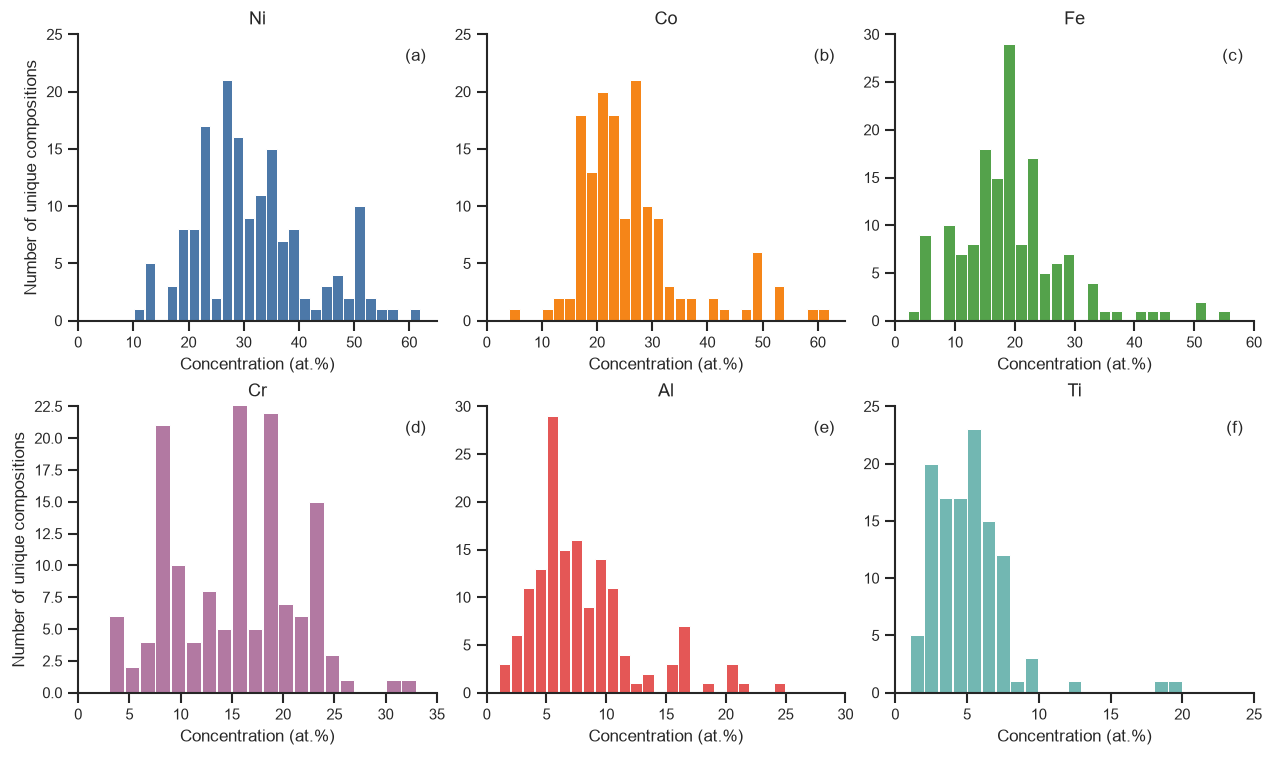

In [27]:
## %% [markdown]
# # 03. PCA композиционного пространства и пул незаполненных областей
# Проект: Fe-Ni-Co-Al-Cr-Ti alloy composition space

# %%
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

from src.alloy_space.descriptors import calculate_descriptors

FIGURES_DIR = BASE_DIR / "outputs" / "figures"
TABLES_DIR = BASE_DIR / "outputs" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", font_scale=1.05)
plt.rcParams['figure.dpi'] = 120

# 1. Загрузка уникальных составов и распределения базовых элементов
df_comp = pd.read_parquet(
    BASE_DIR / "data" / "processed" / "dataset_compositions_unique.parquet"
)

BASE_6 = ["Ni", "Co", "Fe", "Cr", "Al", "Ti"]
missing = [el for el in BASE_6 if el not in df_comp.columns]
if missing:
    raise ValueError(f"Нет колонок базовых элементов: {missing}")

N_ALLOYS = len(df_comp)
X_base6 = df_comp[BASE_6].to_numpy(dtype=float)

if N_ALLOYS == 0:
    raise ValueError("Выборка уникальных составов пуста.")
if not np.isfinite(X_base6).all():
    raise ValueError("В концентрациях есть NaN или бесконечные значения.")
if ((X_base6 < 0) | (X_base6 > 100)).any():
    raise ValueError("Есть концентрации вне диапазона 0–100 ат.%.")

# Общие границы интервалов для всех шести панелей
BIN_WIDTHS = {
    "Ni": 2.0,
    "Co": 2.0,
    "Fe": 2.0,
    "Cr": 1.5,
    "Al": 1.0,
    "Ti": 1.0,
}

ELEMENT_COLORS = {
    "Ni": "#4C78A8",  # синий
    "Co": "#F58518",  # оранжевый
    "Fe": "#54A24B",  # зелёный
    "Cr": "#B279A2",  # фиолетовый
    "Al": "#E45756",  # красный
    "Ti": "#72B7B2",  # бирюзовый
}

Y_MAX = {
    "Ni": 25,
    "Co": 25,
    "Fe": 30,
    "Cr": 22.5,
    "Al": 30,
    "Ti": 25,
}

X_MAX = {
    "Ni": 65,
    "Co": 65,
    "Fe": 60,
    "Cr": 35,
    "Al": 30,
    "Ti": 25,
}

with plt.rc_context({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.transparent": False,
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,
}):
    fig_hist, axes_hist = plt.subplots(
        2, 3,
        figsize=(10.5, 6.2),
        sharex=False,
        sharey=False,
        constrained_layout=True,
    )


    for panel, ax, element in zip("abcdef", axes_hist.flat, BASE_6):
        values = df_comp[element].to_numpy(dtype=float)
        values = values[values > 0]

        bin_width = BIN_WIDTHS[element]
        if bin_width <= 0:
            raise ValueError(f"{element}: ширина интервала должна быть положительной.")

        max_value = values.max() if values.size else 0.0
        n_bins = max(1, int(np.ceil(max_value / bin_width)))
        bin_edges = np.arange(n_bins + 1) * bin_width

        counts, _, _ = ax.hist(
            values,
            bins=bin_edges,
            rwidth=0.95,
            color=ELEMENT_COLORS[element],
            edgecolor="white",
            linewidth=0.6,
        )

        if int(counts.sum()) != len(values):
            raise ValueError(
                f"{element}: не все ненулевые концентрации попали в гистограмму."
            )

        ax.set_title(element)
        ax.set_xlabel("Concentration (at.%)")
        ax.set_xlim(0, X_MAX[element])
        ax.set_ylim(0, Y_MAX[element])
        ax.text(
            0.97, 0.95, f"({panel})",
            transform=ax.transAxes,
            ha="right", va="top",
        )
        ax.tick_params(axis="x", labelbottom=True)
        ax.grid(False)

    for ax in axes_hist[:, 0]:
        ax.set_ylabel("Number of unique compositions")

    sns.despine(fig=fig_hist)

    hist_output = FIGURES_DIR / "base6_concentration_histograms"
    fig_hist.savefig(hist_output.with_suffix(".pdf"), bbox_inches="tight")
    fig_hist.savefig(
        hist_output.with_suffix(".png"),
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()

In [ ]:
    for panel, ax, element in zip("abcdef", axes_hist.flat, BASE_6):
        values = df_comp[element].to_numpy(dtype=float)
        values = values[values > 0]

        bin_width = BIN_WIDTHS[element]
        if bin_width <= 0:
            raise ValueError(f"{element}: ширина интервала должна быть положительной.")

        max_value = values.max() if values.size else 0.0
        n_bins = max(1, int(np.ceil(max_value / bin_width)))
        bin_edges = np.arange(n_bins + 1) * bin_width

        counts, _, _ = ax.hist(
            values,
            bins=bin_edges,
            rwidth=0.95,
            color=ELEMENT_COLORS[element],
            edgecolor="white",
            linewidth=0.6,
        )

        if int(counts.sum()) != len(values):
            raise ValueError(
                f"{element}: не все ненулевые концентрации попали в гистограмму."
            )

    # Далее ваши существующие настройки заголовка и осей

In [2]:
# %%
# 2. PCA на стандартизованных концентрациях базовых элементов
scaler_base6 = StandardScaler()
X_base6_scaled = scaler_base6.fit_transform(X_base6)

pca = PCA(n_components=len(BASE_6))
X_pca_full = pca.fit_transform(X_base6_scaled)

for i in range(3):
    df_comp[f'PC{i + 1}'] = X_pca_full[:, i]

exp_var = pca.explained_variance_ratio_ * 100
variance_table = pd.DataFrame({
    'Component': [f'PC{i + 1}' for i in range(len(exp_var))],
    'Explained variance, %': exp_var.round(2),
    'Cumulative, %': np.cumsum(exp_var).round(2)})
print(variance_table.to_string(index=False))

loadings = pd.DataFrame(pca.components_[:3].T, columns=['PC1', 'PC2', 'PC3'], index=BASE_6)
print("\n=== Нагрузки элементов на PC1–PC3 ===")
print(loadings.round(3))
print("\n=== Вклад элемента в дисперсию оси, % ===")
print(((loadings ** 2) * 100).round(1))

with pd.ExcelWriter(TABLES_DIR / "pca_summary.xlsx", engine="openpyxl") as writer:
    variance_table.to_excel(writer, sheet_name="Explained_variance", index=False)
    loadings.round(4).rename_axis("Element").reset_index().to_excel(
        writer, sheet_name="Loadings_PC1-3", index=False)

Component  Explained variance, %  Cumulative, %
      PC1                  28.89          28.89
      PC2                  24.10          52.99
      PC3                  18.01          71.00
      PC4                  15.94          86.94
      PC5                  12.17          99.12
      PC6                   0.88         100.00

=== Нагрузки элементов на PC1–PC3 ===
      PC1    PC2    PC3
Ni  0.667 -0.111  0.020
Co -0.500 -0.569 -0.180
Fe -0.229  0.658 -0.304
Cr -0.127  0.126  0.927
Al  0.301  0.299 -0.117
Ti  0.381 -0.354 -0.052

=== Вклад элемента в дисперсию оси, % ===
     PC1   PC2   PC3
Ni  44.5   1.2   0.0
Co  25.0  32.4   3.2
Fe   5.2  43.2   9.2
Cr   1.6   1.6  85.9
Al   9.1   9.0   1.4
Ti  14.5  12.6   0.3


In [3]:
# %%
# 3. 3D-сетка, возврат в состав, L1_2-окно, пул
MARGIN, GRID_N = 0.15, 35
pcs = df_comp[['PC1', 'PC2', 'PC3']].values

axes_1d = [np.linspace(pcs[:, k].min() - MARGIN * np.ptp(pcs[:, k]),
                       pcs[:, k].max() + MARGIN * np.ptp(pcs[:, k]), GRID_N) for k in range(3)]
grid = np.column_stack([g.ravel() for g in np.meshgrid(*axes_1d)])

nn = NearestNeighbors(n_neighbors=1).fit(pcs)
df_grid = pd.DataFrame(grid, columns=['PC1', 'PC2', 'PC3'])
df_grid['dist_to_nearest_alloy'] = nn.kneighbors(grid)[0].ravel()

full = np.zeros((len(grid), pca.n_components_))
full[:, :3] = grid
comp = pd.DataFrame(scaler_base6.inverse_transform(pca.inverse_transform(full)), columns=BASE_6)
df_grid = pd.concat([df_grid, comp], axis=1)

df_valid = df_grid[(df_grid[BASE_6] >= -1.0).all(axis=1)].copy()
df_valid[BASE_6] = df_valid[BASE_6].clip(lower=0)
df_valid[BASE_6] = df_valid[BASE_6].div(df_valid[BASE_6].sum(axis=1), axis=0) * 100.0
df_valid = pd.concat([df_valid, calculate_descriptors(df_valid)], axis=1)

def in_l12_window(d):
    return ((d['VEC'] >= 7.85)
            & d['Al_plus_Ti'].between(8.0, 12.5)
            & d['Al_to_Ti_ratio'].between(0.9, 2.2)
            & (d['delta_atomic_radius'] <= 6.0))

valid_l12 = df_valid[in_l12_window(df_valid)].copy()
gap_threshold = float(np.percentile(valid_l12['dist_to_nearest_alloy'], 85))
gap_pool = valid_l12[valid_l12['dist_to_nearest_alloy'] >= gap_threshold].copy()

print(f"Узлов сетки: {len(df_grid)}; физически валидных: {len(df_valid)}; "
      f"в L1_2-окне: {len(valid_l12)}; порог 85-го перцентиля: {gap_threshold:.3f}; пул: {len(gap_pool)}")
pool_cols = BASE_6 + ['VEC', 'Al_plus_Ti', 'Al_to_Ti_ratio', 'delta_atomic_radius', 'dist_to_nearest_alloy']
gap_pool[pool_cols].round(2).to_excel(TABLES_DIR / "pca3d_gap_pool_base6.xlsx", index=False)

Узлов сетки: 42875; физически валидных: 12798; в L1_2-окне: 887; порог 85-го перцентиля: 0.907; пул: 133


In [4]:
# %%
# 4. Кандидаты (выбраны вручную по интерактивному 3D-графику) и выплавленные образцы
CANDIDATES = pd.DataFrame([
    [38.72, 29.72,  4.76, 14.88, 5.69, 6.24],   # 1
    [33.66, 23.78,  5.91, 27.30, 5.02, 4.33],   # 2
    [37.55, 20.18,  0.60, 31.72, 4.88, 5.07],   # 3
    [41.00, 15.44,  5.10, 26.29, 6.85, 5.32],   # 4
    [28.97, 22.47, 12.80, 27.40, 5.52, 2.84],   # 5
    [32.66, 36.37, 16.05,  3.29, 6.52, 5.12],   # 6
    [26.29, 40.56, 20.55,  2.88, 5.88, 3.84],   # 7
    [26.83, 42.40, 14.95,  6.82, 4.70, 4.31],   # 8
    [25.17, 48.38, 16.64,  0.89, 4.45, 4.47],   # 9
    [22.18, 45.42, 23.38,  0.41, 5.37, 3.24],   # 10
    [41.92, 21.55,  1.44, 22.80, 6.01, 6.28],   # 11
    [41.41, 17.89,  0.62, 28.42, 5.87, 5.79],   # 12
], columns=BASE_6)
CANDIDATES.insert(0, 'Alloy_Number', range(1, len(CANDIDATES) + 1))
CANDIDATES['Cluster'] = ['Upper'] * 5 + ['Lower'] * 5 + ['Upper'] * 2   # 11-12: проверьте

def project(comp_df):
    z = pca.transform(scaler_base6.transform(comp_df[BASE_6].values.astype(float)))
    out = comp_df.copy()
    out[['PC1', 'PC2', 'PC3']] = z[:, :3]
    return out

cand = project(CANDIDATES)
cand = pd.concat([cand, calculate_descriptors(cand)], axis=1)
cand['in_L12_window'] = in_l12_window(cand)
cand['dist_to_nearest_alloy'] = nn.kneighbors(cand[['PC1', 'PC2', 'PC3']].values)[0].ravel()
cand['beyond_gap_threshold'] = cand['dist_to_nearest_alloy'] >= gap_threshold
print("Суммы составов кандидатов:", CANDIDATES[BASE_6].sum(axis=1).round(2).tolist())
print(cand[['Alloy_Number', 'Cluster', 'Al_plus_Ti', 'Al_to_Ti_ratio', 'VEC',
            'in_L12_window', 'dist_to_nearest_alloy', 'beyond_gap_threshold']].round(2).to_string(index=False))
cand.round(3).to_excel(TABLES_DIR / "candidates_12.xlsx", index=False)

melting_raw = pd.read_excel(BASE_DIR / "data" / "raw" / "HEA_melting_results.xlsx")
melting_raw.columns = [c.strip() for c in melting_raw.columns]
assert set(BASE_6) <= set(melting_raw.columns), "В файле выплавок нет колонок базовых элементов"
melted = project(melting_raw[BASE_6].astype(float))
melted['Alloy_Number'] = range(13, 13 + len(melted))
other_cols = [c for c in melting_raw.columns if c not in BASE_6]
if other_cols:
    melted[other_cols] = melting_raw[other_cols].values
print("Суммы составов выплавок:", melted[BASE_6].sum(axis=1).round(2).tolist())

Суммы составов кандидатов: [100.01, 100.0, 100.0, 100.0, 100.0, 100.01, 100.0, 100.01, 100.0, 100.0, 100.0, 100.0]
 Alloy_Number Cluster  Al_plus_Ti  Al_to_Ti_ratio  VEC  in_L12_window  dist_to_nearest_alloy  beyond_gap_threshold
            1   Upper       11.93            0.91 8.24           True                   1.04                  True
            2   Upper        9.35            1.16 7.94           True                   0.92                  True
            3   Upper        9.95            0.96 7.87           True                   1.26                  True
            4   Upper       12.17            1.29 7.89           True                   0.92                  True
            5   Upper        8.36            1.94 7.87           True                   0.97                  True
            6   Lower       11.64            1.27 8.42           True                   0.97                  True
            7   Lower        9.72            1.53 8.43           True           

In [5]:
# %%
# 5. Итоговый график
import plotly.graph_objects as go

LABELS = {'lit': 'Literature alloys', 'pool': 'Gap pool (hidden by default)',
          'cand': 'Candidate alloys', 'melt': 'Melted samples'}
CAMERA = dict(eye=dict(x=1.6, y=1.6, z=0.9))

def fmt(v):
    return f"{v:.2f}" if isinstance(v, (float, np.floating)) else str(v)

def hover_text(df, prefix=None, extra=()):
    out = []
    for i, (_, r) in enumerate(df.iterrows()):
        head = f"<b>{prefix[i]}</b><br>" if prefix is not None else ""
        comps = ", ".join(f"{c}={r[c]:.1f}" for c in BASE_6)
        tail = "".join(f"<br>{c}={fmt(r[c])}" for c in extra)
        out.append(head + comps + tail)
    return out

# %%
# Связи между кандидатами верхнего кластера (бывшие жёлтые + бывшие бирюзовые)
UPPER_LINKS = [
    (5, 4), (5, 2), (5, 3), (3, 4), (3, 2), (1, 4), (1, 2),            # были жёлтыми
    (12, 2), (12, 3), (12, 4), (12, 11), (11, 1), (11, 2), (11, 4),    # были бирюзовыми
]
LOWER_LINKS = [(10, 7), (10, 9), (10, 8), (8, 7), (8, 9), (6, 8), (6, 9), (6, 7)]   # нижний кластер настроим позже
LINKS = sorted({tuple(sorted(p)) for p in UPPER_LINKS + LOWER_LINKS})
LINK_COLOR = 'goldenrod'

points_by_number = {int(r.Alloy_Number): (r.PC1, r.PC2, r.PC3) for r in cand.itertuples()}
assert all(a in points_by_number and b in points_by_number for a, b in LINKS), "Связь на несуществующий номер"

def links_trace(pairs, color=LINK_COLOR, name='Links between candidates', width=4):
    xs, ys, zs = [], [], []
    for a, b in pairs:
        pa, pb = points_by_number[a], points_by_number[b]
        xs += [pa[0], pb[0], None]
        ys += [pa[1], pb[1], None]
        zs += [pa[2], pb[2], None]
    return go.Scatter3d(x=xs, y=ys, z=zs, mode='lines',
                        line=dict(color=color, width=width),
                        name=name, hoverinfo='skip')

def make_figure(show_pool=False, show_window=False, links=None, width=1000, height=750):
    fig = go.Figure()
    fig.add_trace(go.Scatter3d(
        x=df_comp['PC1'], y=df_comp['PC2'], z=df_comp['PC3'], mode='markers',
        marker=dict(size=5, color='steelblue', opacity=0.7, line=dict(width=0.5, color='black')),
        name=f"{LABELS['lit']} (n={len(df_comp)})",
        text=hover_text(df_comp), hoverinfo='text'))
    if show_window:
        fig.add_trace(go.Scatter3d(
        x=valid_l12['PC1'], y=valid_l12['PC2'], z=valid_l12['PC3'], mode='markers',
        marker=dict(size=3, color=valid_l12['dist_to_nearest_alloy'], colorscale='Viridis',
                    cmin=0, cmax=valid_l12['dist_to_nearest_alloy'].max(),
                    opacity=0.5, showscale=True,
                    colorbar=dict(title='dist to nearest<br>literature alloy', len=0.6)),
        name=f"L1₂-window nodes (n={len(valid_l12)})",
        text=hover_text(valid_l12, extra=['Al_plus_Ti', 'Al_to_Ti_ratio', 'VEC',
                                          'delta_atomic_radius', 'dist_to_nearest_alloy']),
        hoverinfo='text'))
    if show_pool:
        fig.add_trace(go.Scatter3d(
            x=gap_pool['PC1'], y=gap_pool['PC2'], z=gap_pool['PC3'], mode='markers',
            marker=dict(size=5, color='gray', opacity=0.6, symbol='circle-open', line=dict(width=1, color='gray')),
            name=f"{LABELS['pool']} (n={len(gap_pool)})",
            text=hover_text(gap_pool, extra=['dist_to_nearest_alloy']),
            hoverinfo='text', visible=True))
    fig.add_trace(go.Scatter3d(
        x=cand['PC1'], y=cand['PC2'], z=cand['PC3'], mode='markers+text',
        marker=dict(size=9, color='gold', symbol='diamond', line=dict(width=2, color='black')),
        text=cand['Alloy_Number'].astype(str), textposition='top center',
        textfont=dict(size=13, color='black'),
        hovertext=hover_text(cand, prefix=[f"Candidate {n}" for n in cand['Alloy_Number']],
                             extra=['Cluster', 'dist_to_nearest_alloy']),
        hoverinfo='text', name=f"{LABELS['cand']} (n={len(cand)})"))
    fig.add_trace(go.Scatter3d(
        x=melted['PC1'], y=melted['PC2'], z=melted['PC3'], mode='markers+text',
        marker=dict(size=11, color='limegreen', symbol='square', line=dict(width=2, color='black')),
        text=melted['Alloy_Number'].astype(str), textposition='top center',
        textfont=dict(size=13, color='darkgreen'),
        hovertext=hover_text(melted, prefix=[f"Sample {n}" for n in melted['Alloy_Number']],
                             extra=other_cols),
        hoverinfo='text', name=f"{LABELS['melt']} (n={len(melted)})"))
    if links:
        fig.add_trace(links_trace(links))
    fig.update_layout(
        template='plotly_white', width=width, height=height,
        legend=dict(itemsizing='constant'),
        scene=dict(xaxis_title=f"PC1 ({exp_var[0]:.1f}%)",
                   yaxis_title=f"PC2 ({exp_var[1]:.1f}%)",
                   zaxis_title=f"PC3 ({exp_var[2]:.1f}%)",
                   camera=CAMERA))
    return fig


make_figure(show_pool=True, show_window=True, links=LINKS).write_html(
    str(FIGURES_DIR / "pca3d_composition_space.html"))

fig_static = make_figure(show_pool=True, show_window=True, links=LINKS)
fig_static.show()